# Calibrating the similarity threshold

Above which cosine similarity should two transcriptional profiles be called
similar? A flat cut-off will not do: the similarity of two *random* profiles
depends on how many genes are compared, so the same number means different
things for a 100-gene and a 5,000-gene signature.

The threshold is therefore defined against a null distribution,

$Th(N) = \mu_N + k \cdot \sigma_N$

with $\mu_N$, $\sigma_N$ the mean and standard deviation of the cosine
similarity between pairs of random normal profiles of $N$ genes. This notebook
determines the constant $k$, which
`02_cell_to_tissue_similarity.ipynb` then uses throughout.

**Logic**: profiles of the *same compound* at neighbouring doses ought to be
called similar. The lowest similarity observed among such profiles is
therefore a floor the threshold must not exceed, and $k$ is read off from it.

**Produces** Figure 8 and Supplementary Figure S2.

In [1]:
import sys

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

sys.path.insert(0, "..")
from common import flatten, simulate_null_cosine

FIGURES = "../../figures"
DATA = "../../data/external"

FLATTEN_CUTOFF = 2.0      # |z| below which a value is treated as no signal
N_LANDMARK = 978          # size of the landmark feature space
N_SIMULATIONS = 100_000

## 1. Null distribution of cosine similarity

Supplementary Figure S2: the threshold as a function of signature length, for
several values of $k$. It falls steeply with the number of genes — which is
exactly why the threshold cannot be a constant.

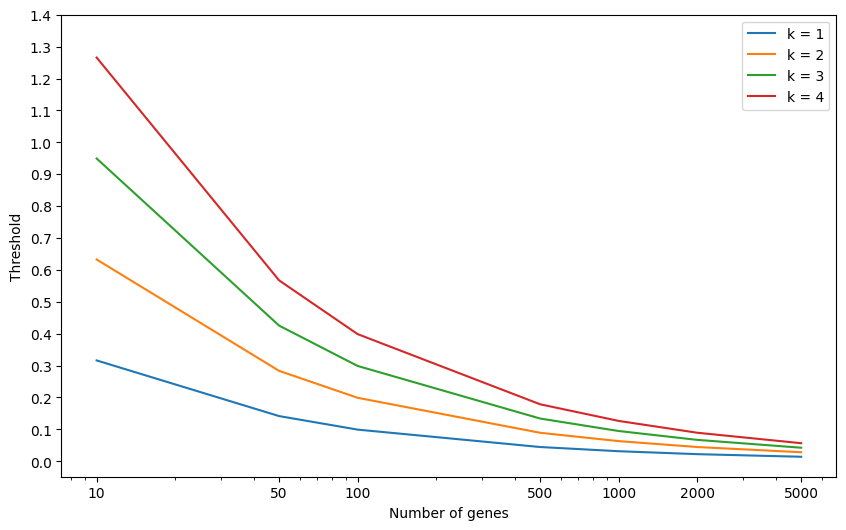

In [2]:
gene_counts = [10, 50, 100, 500, 1000, 2000, 5000]
null = {n: simulate_null_cosine(n, N_SIMULATIONS) for n in gene_counts}

fig, ax = plt.subplots(figsize=(10, 6))
for k in (1, 2, 3, 4):
    ax.plot(gene_counts, [mu + k * sigma for mu, sigma in null.values()],
            label=f"k = {k}")
ax.set_xlabel("Number of genes")
ax.set_ylabel("Threshold")
ax.set_xscale("log")
ax.set_xticks(gene_counts, gene_counts)
ax.set_yticks(np.arange(0, 1.5, 0.1))
ax.legend()
for ext in ("png", "pdf"):
    fig.savefig(f"{FIGURES}/Supplementary_Figure-S2_Thresholds_Simulations_Plot.{ext}",
                dpi=500, bbox_inches="tight", pad_inches=0.1)
plt.show()

## 2. Self-similarity of three compounds

Three compounds with more than ten MCF7 signatures at 24 h are used as
references. Similarities are computed after **flattening**: values with
`|z| < 2` are set to zero, so the comparison rests on genes the compound
actually moves rather than on the inert bulk.

Two computations, deliberately different:

- **Figure 8** shows the full dose-by-dose matrix of each compound (12-13
  profiles), additionally dropping genes that are zero in *both* profiles of
  a pair, since such genes say nothing about either.
- **The floor** (section 3) is read from the low-dose subset only — the
  regime where the response is weakest and two profiles of the same compound
  are hardest to recognise as similar. That is the demanding case the
  threshold has to survive.

In [3]:
REFERENCE_COMPOUNDS = {
    "ACGUYXCXAPNIKK-UHFFFAOYSA-N": ("Hexachlorophene", ["0.12 uM", "0.125 uM", "0.25 uM"]),
    "AFSDNFLWKVMVRB-UHFFFAOYSA-N": ("Ellagic Acid", ["0.08 uM", "0.125 uM", "0.25 uM"]),
    "AHLBNYSZXLDEJQ-FWEHEUNISA-N": ("Orlistat", ["0.03 uM", "0.04 uM", "0.08 uM", "0.125 uM"]),
}

mcf7 = pd.read_csv(f"{DATA}/L1000/L1000_MCF7_landmarks_bestTAS.csv")
mcf7 = mcf7[(mcf7["inchikey"] != "restricted") & (mcf7["time"] == "24 h")]
print(f"{len(mcf7)} landmark signatures at 24 h")

35898 landmark signatures at 24 h


In [4]:
def similarity_matrix(profiles, drop_shared_zeros, cutoff=FLATTEN_CUTOFF):
    """Pairwise cosine similarity between the profiles of one compound."""
    values = flatten(profiles, cutoff)
    if not drop_shared_zeros:
        return cosine_similarity(values)

    n = len(values)
    matrix = np.ones((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            a, b = values[i], values[j]
            keep = ~((a == 0) & (b == 0))
            matrix[i, j] = matrix[j, i] = cosine_similarity(
                a[keep].reshape(1, -1), b[keep].reshape(1, -1)
            )[0][0]
    return matrix


def lowest_pair(matrix):
    """Least similar pair of a square similarity matrix (off-diagonal minimum)."""
    return matrix[~np.eye(len(matrix), dtype=bool)].min()


matrices, labels, names, floors = [], [], [], []
for inchikey, (name, doses) in REFERENCE_COMPOUNDS.items():
    all_profiles = mcf7[mcf7["inchikey"] == inchikey]
    low_dose = all_profiles[all_profiles["dose"].isin(doses)]

    matrices.append(similarity_matrix(all_profiles.iloc[:, 7:], drop_shared_zeros=True))
    labels.append([f"{d} -- {t}" for d, t in zip(all_profiles["dose"],
                                                 all_profiles["time"])])
    names.append(name)
    floors.append(
        lowest_pair(similarity_matrix(low_dose.iloc[:, 7:], drop_shared_zeros=False))
    )
    print(f"{name:18s}: {len(all_profiles):2d} profiles "
          f"({len(low_dose)} at low dose), floor {floors[-1]:.4f}")

Hexachlorophene   : 13 profiles (3 at low dose), floor 0.1028
Ellagic Acid      : 12 profiles (3 at low dose), floor 0.1368
Orlistat          : 12 profiles (4 at low dose), floor 0.1048


In [5]:
# Figure 8.
fig = plt.figure(figsize=(75, 25))
grid = gridspec.GridSpec(1, 4, width_ratios=[1, 1, 1, 0.05])
axes = [plt.subplot(grid[i]) for i in range(3)]
cbar_ax = plt.subplot(grid[3])

for i, ax in enumerate(axes):
    sns.heatmap(
        matrices[i], ax=ax, cmap="vlag", vmin=-1, vmax=1, square=True,
        xticklabels=labels[i], yticklabels=labels[i],
        cbar=(i == 2), cbar_ax=cbar_ax if i == 2 else None,
    )
    ax.set_title(f"{names[i]}\n", fontsize=40)
    ax.tick_params(axis="y", rotation=0, labelsize=30)
    ax.tick_params(axis="x", rotation=90, labelsize=30)

fig.tight_layout()
cbar_ax.tick_params(labelsize=30)
for ext in ("png", "pdf"):
    fig.savefig(f"{FIGURES}/Figure-8_Cutoff_Cosine_3Cmpd_Empir.{ext}",
                dpi=500, bbox_inches="tight", pad_inches=0.1)

# Not shown inline: the figure is 75 x 25 inches, so any on-screen preview would
# be both unreadable and heavy enough to stop this notebook rendering.
# Open figures/Figure-8_Cutoff_Cosine_3Cmpd_Empir.pdf for the legible version.
plt.close(fig)

## 3. The constant k

The empirical floor is the mean of the three lowest self-similarities. Solving
$Th(N) = \mu_N + k\sigma_N$ for $k$ at the landmark signature length gives the
constant used in `02_cell_to_tissue_similarity.ipynb`.

$\mu_N$ and $\sigma_N$ are Monte-Carlo estimates, so $k$ carries a sampling
error: across independent runs of 100,000 simulations its standard deviation is
about 0.006. Ten runs are averaged to damp it, and $k$ should be read as
3.59 ± 0.01 rather than as an exact constant — the published value is 3.595.

In [6]:
empirical_floor = np.mean(floors)

# Averaged over ten independent simulations, as in the original analysis: a
# single run of 100,000 draws leaves enough noise on sigma to move k by ~0.01.
N_REPEATS = 10
mus, sigmas = zip(*[simulate_null_cosine(N_LANDMARK, N_SIMULATIONS, seed=s) for s in range(N_REPEATS)])
mu, sigma = np.mean(mus), np.mean(sigmas)
k = (empirical_floor - mu) / sigma

print(f"empirical floor         {empirical_floor:.5f}")
print(f"null at N={N_LANDMARK}  mu={mu:.6f}  sigma={sigma:.6f}")
print(f"k                       {k:.3f}   (published: 3.595)")

empirical floor         0.11479
null at N=978  mu=0.000004  sigma=0.031938
k                       3.594   (published: 3.595)
